In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make visualizations look cleaner
sns.set_theme(style="whitegrid")

# Display more columns in the output
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

In [1]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

NameError: name 'pd' is not defined

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 891
Number of columns: 15


In [6]:
print(df.columns.tolist())

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [8]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
df.describe(include="object")

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [10]:
missing = df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))

deck           688
age            177
embarked         2
embark_town      2
dtype: int64


In [11]:
missing_percent = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percent
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values("Missing Percentage", ascending=False)

missing_summary

,Missing Values,Missing Percentage
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 107


In [13]:
df_raw = df.copy()
df = df_raw.copy()

In [14]:
age_median = df["age"].median()

df["age"] = df["age"].fillna(age_median)

print("Missing ages remaining:", df["age"].isnull().sum())

Missing ages remaining: 0


In [15]:
embarked_mode = df["embarked"].mode()[0]

df["embarked"] = df["embarked"].fillna(embarked_mode)

print("Missing embarked values:", df["embarked"].isnull().sum())

Missing embarked values: 0


In [16]:
df = df.drop(columns=["deck"])

In [17]:
duplicates_before = df.duplicated().sum()

df = df.drop_duplicates()

print("Duplicates found:", duplicates_before)
print("Duplicates remaining:", df.duplicated().sum())

Duplicates found: 116
Duplicates remaining: 0


In [18]:
print(df.dtypes)

survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
embark_town     object
alive           object
alone             bool
dtype: object


In [19]:
df["sex"] = df["sex"].str.strip().str.lower()
df["embarked"] = df["embarked"].str.strip().str.upper()

In [20]:
print("Original shape:", df_raw.shape)
print("Cleaned shape:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows after cleaning:", df.duplicated().sum())

df.head()

Original shape: (891, 15)
Cleaned shape: (775, 14)

Missing values after cleaning:
embark_town    2
dtype: int64

Duplicate rows after cleaning: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [21]:
df.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,775.00,775.00,775.00,775.00,775.00,775.00
mean,0.41,2.25,29.58,0.53,0.42,34.88
std,0.49,0.85,13.77,0.99,0.84,52.41
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,1.00,21.00,0.00,0.00,8.05
50%,0.00,3.00,28.00,0.00,0.00,15.90
75%,1.00,3.00,36.00,1.00,1.00,34.20
max,1.00,3.00,80.00,8.00,6.00,512.33


In [22]:
for col in ["sex", "class", "embarked", "survived"]:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts(dropna=False))


Distribution of sex:
sex
male      483
female    292
Name: count, dtype: int64

Distribution of class:
class
Third     401
First     210
Second    164
Name: count, dtype: int64

Distribution of embarked:
embarked
S    562
C    155
Q     58
Name: count, dtype: int64

Distribution of survived:
survived
0    455
1    320
Name: count, dtype: int64


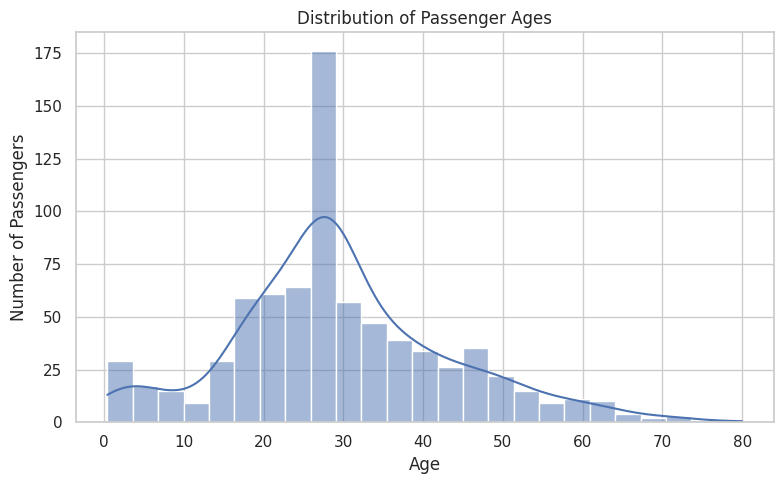

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=25, kde=True)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

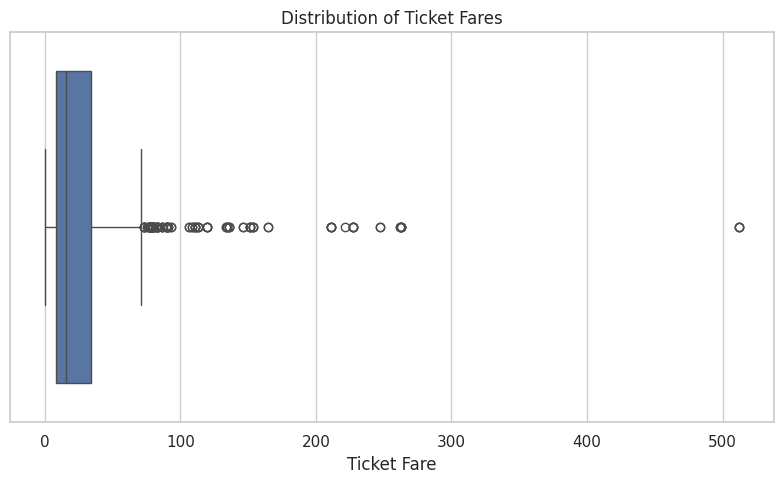

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="fare")

plt.title("Distribution of Ticket Fares")
plt.xlabel("Ticket Fare")
plt.tight_layout()
plt.show()

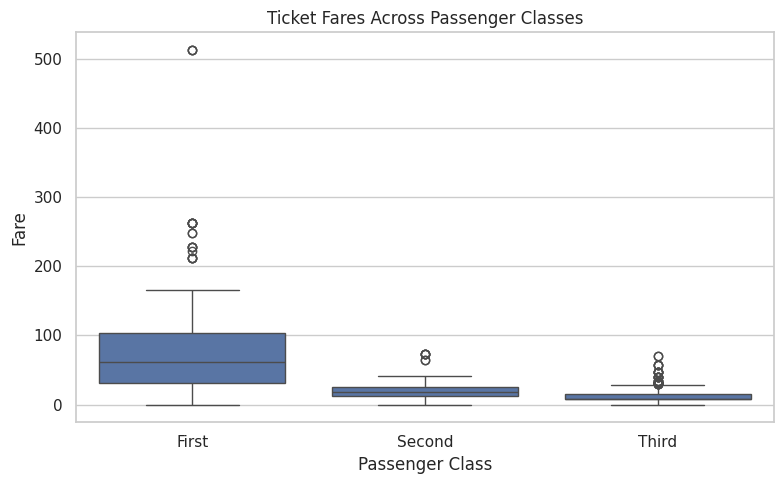

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="class", y="fare", order=["First", "Second", "Third"])

plt.title("Ticket Fares Across Passenger Classes")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

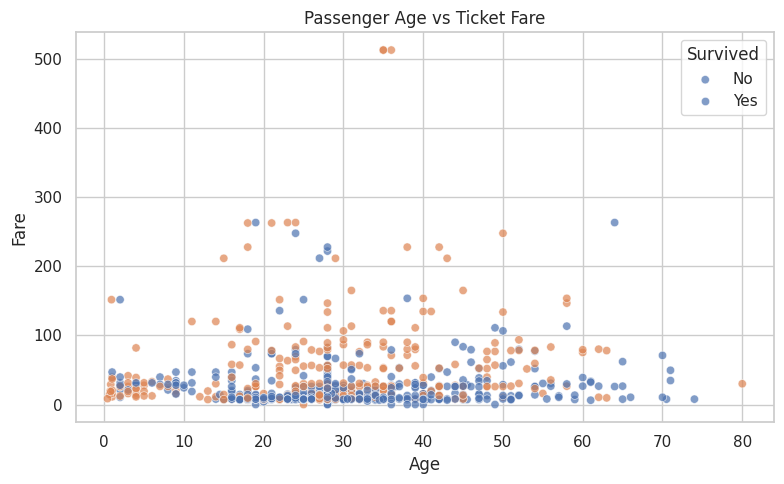

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="fare",
    hue="survived",
    alpha=0.7
)

plt.title("Passenger Age vs Ticket Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

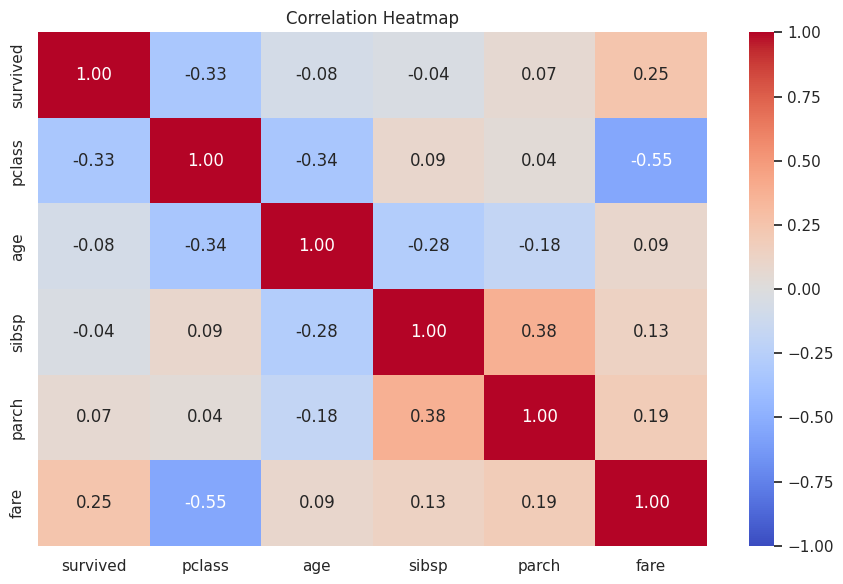

In [27]:
numeric_cols = ["survived", "pclass", "age", "sibsp", "parch", "fare"]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

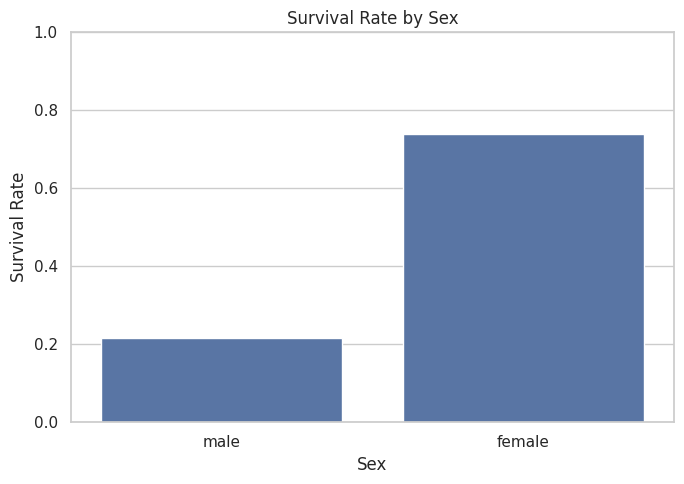

In [28]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="sex", y="survived", errorbar=None)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [29]:
survival_by_sex = df.groupby("sex")["survived"].mean().mul(100).round(2)

print("Survival rate by sex (%):")
print(survival_by_sex)

Survival rate by sex (%):
sex
female    73.97
male      21.53
Name: survived, dtype: float64


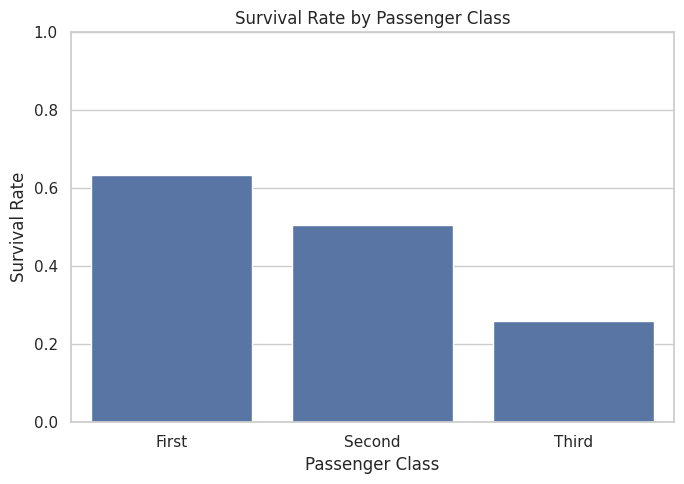

In [30]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="class",
    y="survived",
    order=["First", "Second", "Third"],
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [31]:
survival_by_class = (
    df.groupby("class", observed=False)["survived"]
      .mean()
      .mul(100)
      .round(2)
)

print("Survival rate by class (%):")
print(survival_by_class)

Survival rate by class (%):
class
First     63.33
Second    50.61
Third     25.94
Name: survived, dtype: float64


In [32]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing cells",
        "Duplicate rows"
    ],
    "Before Cleaning": [
        df_raw.shape[0],
        df_raw.shape[1],
        int(df_raw.isnull().sum().sum()),
        int(df_raw.duplicated().sum())
    ],
    "After Cleaning": [
        df.shape[0],
        df.shape[1],
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum())
    ]
})

cleaning_summary

,Metric,Before Cleaning,After Cleaning
0,Rows,891,775
1,Columns,15,14
2,Missing cells,869,2
3,Duplicate rows,107,0


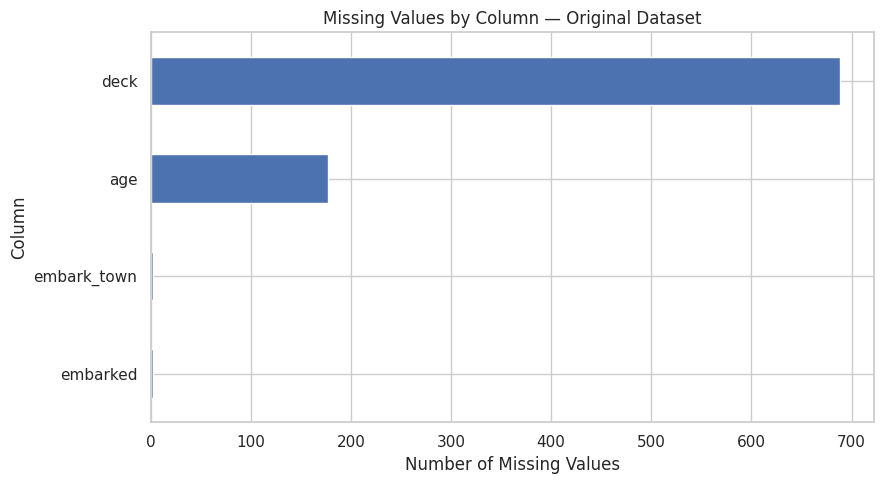

In [33]:
missing_counts = df_raw.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values()

plt.figure(figsize=(9, 5))

missing_counts.plot(kind="barh")

plt.title("Missing Values by Column — Original Dataset")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [34]:
df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [35]:
from google.colab import files

files.download("titanic_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

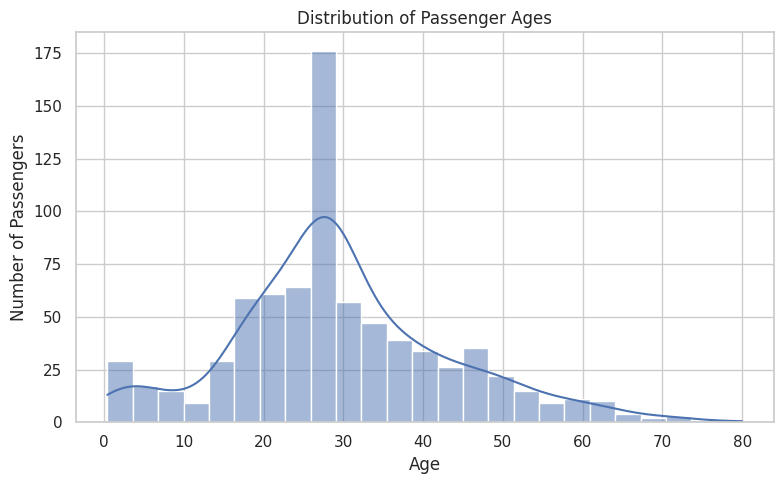

In [36]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=25, kde=True)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()

plt.savefig("age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

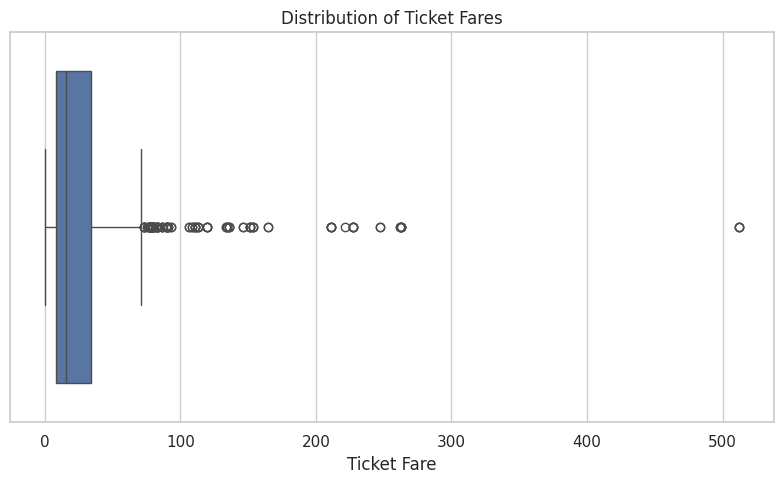

In [37]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="fare")

plt.title("Distribution of Ticket Fares")
plt.xlabel("Ticket Fare")
plt.tight_layout()

plt.savefig("fare_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()


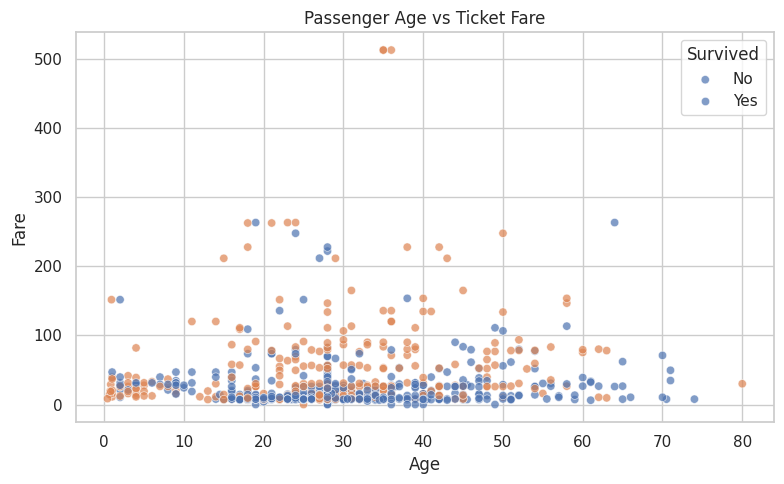

In [38]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="fare",
    hue="survived",
    alpha=0.7
)

plt.title("Passenger Age vs Ticket Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()

plt.savefig("age_vs_fare.png", dpi=300, bbox_inches="tight")
plt.show()


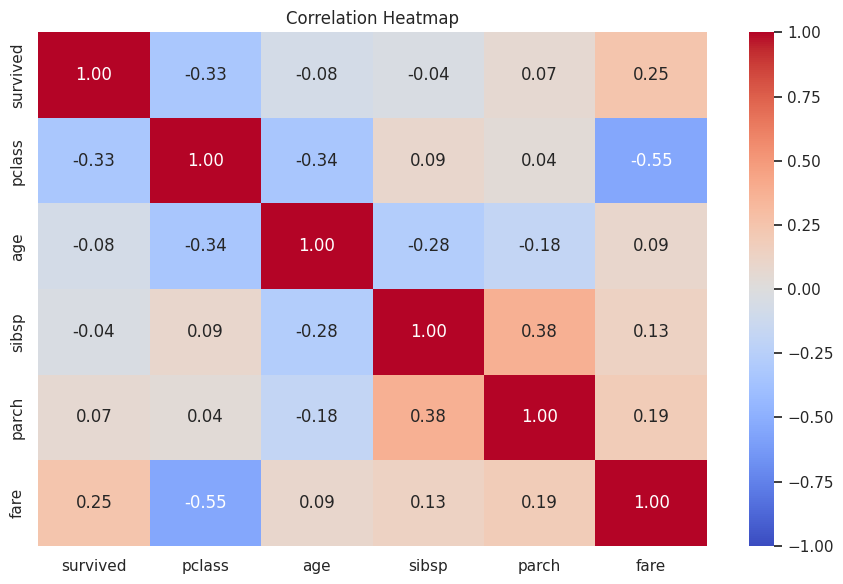

In [39]:

numeric_cols = [
    "survived", "pclass", "age",
    "sibsp", "parch", "fare"
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


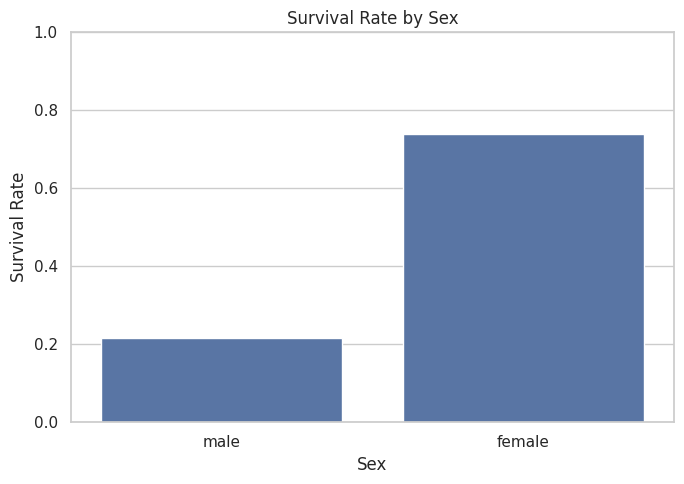

In [40]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="sex",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig("survival_by_sex.png", dpi=300, bbox_inches="tight")
plt.show()


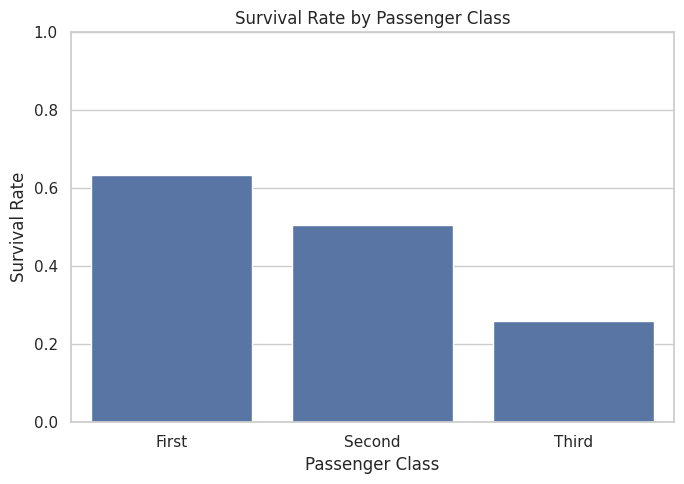

In [41]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="class",
    y="survived",
    order=["First", "Second", "Third"],
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig("survival_by_class.png", dpi=300, bbox_inches="tight")
plt.show()
